In [1]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import polars as pl
import time
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import OrdinalEncoder
import os
import gc
import matplotlib.pyplot as plt
import warnings
import sys
import torch

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset
import random

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
from merlin.loader.torch import Loader
from merlin.io import Dataset as Dataset_merlin

os.environ["CUDA_VISIBLE_DEVICES"] = "0"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = torch.device("cpu")
print(device)

sys.path.append("../src/otto_recommender")
import utils

warnings.filterwarnings("ignore")
tqdm.pandas()

pd.set_option("max_rows", 500)

%matplotlib inline

cuda


In [2]:
def seed_everything(seed):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False  # set True to be faster
    # torch.use_deterministic_algorithms(True)
    print(f"Setting all seeds to be {seed} to reproduce...")


seed_everything(42)

Setting all seeds to be 42 to reproduce...


In [3]:
class Config:
    col_user = "user"
    col_aid = "aid"
    col_type = "type"
    col_n_session = "n_session"
    col_n_day = "n_day"
    col_n_week = "n_week"
    col_dayofweek = "dayofweek"
    col_hour = "hour"
    col_ts = "ts"
    col_num_action = "num_action"
    col_train_seq = "train_seq"
    col_target = "target"
    batch_size_train = 128
    batch_size_infer = 128
    n_epochs = 2
    max_len = 10


config = Config()

In [4]:
print(utils.recall_vals_one_row([1, 2, 3], 2))
print(utils.recall_vals_one_row([1, 2, 3], 4))

True
False


In [5]:
utils.recall_several_targets(candidates=[[1, 2, 3], [1]], targets=[[1, 3, 2], [1, 2]])

0.8

In [6]:
from pandarallel import pandarallel

pandarallel.initialize(nb_workers=16, progress_bar=True, use_memory_fs=False)

INFO: Pandarallel will run on 16 workers.
INFO: Pandarallel will use standard multiprocessing data transfer (pipe) to transfer data between the main process and workers.


In [7]:
%%time

PATH_DATA = '../data/02_intermediate/'
df_train = pl.read_parquet(PATH_DATA + 'df_train_n_session.parquet')
df_test = pl.read_parquet(PATH_DATA + 'df_test_n_session.parquet')
# df_train = df_train.filter(pl.col("user") % 100 == 0)
df_train = df_train.to_pandas()
df_test = df_test.to_pandas()
# df_test = catalog.load("df_test")

df_train.name = "df_train"
df_test.name = "df_test"

df_train = utils.make_date_stats(df_train)
df_test = utils.make_date_stats(df_test)

df_train.drop(['date_day'], axis=1, inplace=True)
df_test.drop(['date_day'], axis=1, inplace=True)

df_train = pl.from_pandas(df_train)
df_test = pl.from_pandas(df_test)

CPU times: user 1min 55s, sys: 25.6 s, total: 2min 21s
Wall time: 2min 4s


In [8]:
%%time

test_users = df_test[config.col_user].unique()
df = pl.concat([df_train, df_test])
df = df.sort(config.col_ts, reverse=True)

df = df.to_pandas()
df[config.col_num_action] = df.groupby(config.col_user)[config.col_aid].cumcount()
df = pl.from_pandas(df)

df = df.with_columns(
    [
        pl.col(config.col_num_action)
        .cast(pl.Int32, strict=True)
        .alias(config.col_num_action),
        pl.col(config.col_n_session)
        .cast(pl.Int32, strict=True)
        .alias(config.col_n_session),
    ]
)

CPU times: user 7min 4s, sys: 48.3 s, total: 7min 52s
Wall time: 1min 2s


In [9]:
del df_train, df_test
gc.collect()

3819

In [10]:
# ### IF DEBUG PIPELINE !!!

# df = df.filter(pl.col("user") % 100 == 0)

In [11]:
counts_aid = df.groupby([config.col_aid]).count().sort("count", reverse=True)

In [12]:
df.head()

user,aid,ts,type,n_session,date,n_day,n_week,dayofweek,hour,num_action
i64,i64,i64,str,i32,datetime[ns],i8,i8,i8,i8,i32
14571581,1100210,1662328791563,"""clicks""",0,2022-09-04 23:59:51.563000064,4,35,6,23,0
14571515,781377,1662328789887,"""clicks""",0,2022-09-04 23:59:49.887000064,4,35,6,23,0
14571170,336732,1662328788088,"""clicks""",0,2022-09-04 23:59:48.088,4,35,6,23,0
14568399,104775,1662328781349,"""clicks""",0,2022-09-04 23:59:41.348999936,4,35,6,23,0
14571580,202353,1662328781067,"""clicks""",0,2022-09-04 23:59:41.067000064,4,35,6,23,0


In [13]:
counts_aid.head()

aid,count
i64,u32
1460571,137874
485256,135892
108125,124885
29735,116215
1733943,106512


In [14]:
df.shape

(223644219, 11)

In [15]:
df = df.to_pandas()

In [16]:
def split_data(df, validation_cut, test_users):
    df_val = df[
        (df[config.col_num_action] <= validation_cut)
        & (df[config.col_user].isin(test_users))
    ]

    df_val_seq = df[
        (df[config.col_num_action] > validation_cut)
        & (df[config.col_user].isin(test_users))
    ]

    df_train = df.drop(df_val.index)
    return df_train, df_val, df_val_seq

In [17]:
%%time

X_train, X_val, X_val_seq = split_data(df, validation_cut=2, test_users=test_users)

CPU times: user 27.6 s, sys: 6.18 s, total: 33.8 s
Wall time: 33.8 s


In [18]:
%%time

trs = 20
counts_aid_filtered = counts_aid.filter(pl.col("count") >= trs).to_pandas()
pad = len(counts_aid_filtered)

ordinal_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=pad)
ordinal_encoder.fit(counts_aid_filtered[config.col_aid].values.reshape(-1, 1))

CPU times: user 617 ms, sys: 4.85 ms, total: 622 ms
Wall time: 617 ms


OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=954978)

In [19]:
%%time

X_train[config.col_aid] = ordinal_encoder.transform(
    X_train[config.col_aid].values.reshape(-1, 1)
).astype(int)
X_val_seq[config.col_aid] = ordinal_encoder.transform(
    X_val_seq[config.col_aid].values.reshape(-1, 1)
).astype(int)

CPU times: user 1min 39s, sys: 4.11 s, total: 1min 44s
Wall time: 1min 44s


In [20]:
%%time

X_train = pl.from_pandas(X_train)
X_train = X_train.sort(config.col_ts)

X_val = pl.from_pandas(X_val)
X_val = X_val.sort(config.col_ts)

X_val_seq = pl.from_pandas(X_val_seq)
X_val_seq = X_val_seq.sort(config.col_ts)

CPU times: user 2min 57s, sys: 48.2 s, total: 3min 45s
Wall time: 19.3 s


In [21]:
X_train.filter(pl.col(config.col_user) == 0)

user,aid,ts,type,n_session,date,n_day,n_week,dayofweek,hour,num_action
i64,i64,i64,str,i32,datetime[ns],i8,i8,i8,i8,i32
0,780767,1659304800025,"""clicks""",0,2022-08-01 00:00:00.024999936,1,31,0,0,275
0,804697,1659304904511,"""clicks""",0,2022-08-01 00:01:44.511000064,1,31,0,0,274
0,673857,1659367439426,"""clicks""",1,2022-08-01 17:23:59.425999872,1,31,0,17,273
0,8442,1659367719997,"""clicks""",1,2022-08-01 17:28:39.996999936,1,31,0,17,272
0,917035,1659367871344,"""clicks""",1,2022-08-01 17:31:11.344,1,31,0,17,271
0,593124,1659367885796,"""clicks""",1,2022-08-01 17:31:25.796,1,31,0,17,270
0,849118,1659369893840,"""carts""",1,2022-08-01 18:04:53.840,1,31,0,18,269
0,237160,1659369898050,"""carts""",1,2022-08-01 18:04:58.049999872,1,31,0,18,268
0,156985,1659370027105,"""orders""",1,2022-08-01 18:07:07.104999936,1,31,0,18,266


In [22]:
%%time

X_train = (
    X_train.groupby([config.col_user])
    .agg(
        [
            pl.col(config.col_aid).list(),
        ]
    ).filter(pl.col(config.col_aid).apply(lambda x: len(x)) >= 2)
)

X_val = (
    X_val.groupby([config.col_user])
    .agg(
        [
            pl.col(config.col_aid).list(),
        ]
    )
)

X_val_seq = (
    X_val_seq.groupby([config.col_user])
    .agg(
        [
            pl.col(config.col_aid).list(),
        ]
    )
)

CPU times: user 4min 20s, sys: 38.4 s, total: 4min 58s
Wall time: 57.1 s


In [23]:
X_train.shape

(13265267, 2)

In [24]:
X_train.filter(pl.col(config.col_user) == 0)

user,aid
i64,list[i64]
0,"[780767, 804697, ... 83448]"


In [25]:
# dict_map_targets = dict()
# dict_map_targets["clicks"] = 0
# dict_map_targets["carts"] = 1
# dict_map_targets["orders"] = 2

In [26]:
counts_aid["aid"].min(), counts_aid["aid"].max()

(0, 1855602)

In [27]:
pad

954978

In [28]:
# %%time

# df_train = df_train.to_pandas()
# df_train['aid_filtered'] = ordinal_encoder.transform(df_train['aid'].values.reshape(-1, 1)).astype(int)
# df_train = pl.from_pandas(df_train)

In [29]:
# counts_aid_type.filter((pl.col("type") == "orders") & (pl.col("count") >= 1)).select(
#     ["aid"]
# ).unique().shape

In [30]:
# counts_aid_type

In [31]:
counts_aid.tail()

aid,count
i64,u32
651154,3
1108274,3
1320306,3
87378,3
967977,3


In [32]:
counts_aid.filter(pl.col("aid") == 1)

aid,count
i64,u32
1,34


In [33]:
# len(counts_aid), len(counts_aid_filtered)

In [34]:
# %%time

# token_to_idx = dict()
# # token_to_idx[-1] = 0 # pad
# token_to_idx[0] = 0 # unknown / pad

# idx = 1
# for i in tqdm(range(len(counts_aid["aid"]))):
#     aid = counts_aid["aid"][i]
#     cnt = counts_aid["count"][i]
#     if cnt > 4:
#         token_to_idx[aid] = idx
#         idx += 1
#     # else:
#     #     token_to_idx[aid] = 0

# idx_to_token = {idx: token for token, idx in token_to_idx.items()}

In [35]:
# len(token_to_idx)

In [36]:
# min(list(token_to_idx.values()))

In [37]:
# token_to_idx[0]

In [38]:
# max_len = 10
# # pad = counts_aid["aid"].max() + 1

# # def get_id_of_token(token):
# #     if token in set(list(token_to_idx.keys())[1:]):
# #         idx = token_to_idx[token]
# #     else:
# #         idx = 0  # unknown
# #     return idx


# # def get_token_if_id(idx):
# #     if idx in set(list(idx_to_token.keys())[1:]):
# #         token = idx_to_token[idx]
# #     else:
# #         token = 0  # unknown
# #     return token


# def to_matrix(names, max_len=max_len, pad=pad, dtype="int32", batch_first=True):
#     """Casts a list of names into rnn-digestible matrix"""

#     max_len = max_len or max(map(len, names))
#     names_ix = np.zeros([len(names), max_len], dtype) + pad

#     for i in tqdm(range(len(names))):
#         cur_name = names[i]
#         line_ix = cur_name[-max_len:]  # last max_len elements
#         # cur_name = cur_name[-max_len:]  # last max_len elements
#         # line_ix = [
#         #     get_id_of_token(cur_name[c]) for c in range(len(cur_name)) if c < max_len
#         # ]
#         names_ix[i, -len(line_ix) :] = line_ix

#     if not batch_first:  # convert [batch, time] into [time, batch]
#         names_ix = np.transpose(names_ix)

#     return names_ix

In [39]:
l = [1, 2, 3]
print(utils.split_list_randomly(l=l, seed=1))
print(utils.split_list_randomly(l=l, seed=2))

([1, 2], [3])
([1], [2, 3])


In [40]:
X_train.head()

user,aid
i64,list[i64]
9382016,"[12848, 12848, ... 789205]"
12624384,"[610154, 801304]"
9303168,"[554388, 554388, ... 219347]"
1535872,"[595279, 407419, 750847]"
1123968,"[226957, 354129, 615506]"


In [41]:
X_train.shape

(13265267, 2)

In [42]:
X_val.head()

user,aid
i64,list[i64]
13438400,[139139]
13413824,"[322370, 1695994, 1317291]"
13814592,"[470541, 7651]"
13651392,[1146205]
13947648,"[175329, 444276, 604389]"


In [43]:
%%time

X_train = X_train.to_pandas()
X_train[config.col_train_seq] = X_train[config.col_aid].parallel_apply(lambda x: x[:-1])
X_train[config.col_target] = X_train[config.col_aid].parallel_apply(lambda x: x[-1])
X_train = pl.from_pandas(X_train)

CPU times: user 2min 21s, sys: 31.7 s, total: 2min 53s
Wall time: 2min 59s


In [44]:
X_train.head()

user,aid,train_seq,target
i64,list[i64],list[i64],i64
9382016,"[12848, 12848, ... 789205]","[12848, 12848, ... 420018]",789205
12624384,"[610154, 801304]",[610154],801304
9303168,"[554388, 554388, ... 219347]","[554388, 554388, ... 533840]",219347
1535872,"[595279, 407419, 750847]","[595279, 407419]",750847
1123968,"[226957, 354129, 615506]","[226957, 354129]",615506


In [45]:
# %%time

# X_train = X_train.with_column((pl.col(config.col_aid).apply(lambda x: x[:-1]).alias(config.col_train_seq)))
# X_train = X_train.with_column((pl.col(config.col_aid).apply(lambda x: x[-1]).alias(config.col_target)))

In [46]:
# %%time

# X_train['val'] = X_train["val"].progress_apply(lambda x: x[0]) #orig_vals

# col_aids = 'train'
# X_train = pl.from_pandas(X_train)
# X_train = (
#     X_train.groupby(["user", 'val'])
#     .agg(
#         [
#             pl.col(col_aids).list(),
#         ]
#     )
#     # .filter(pl.col(col_aids).apply(lambda x: len(x)) >= 2)
# ).sort('user').to_pandas()

# X_train = X_train[['user', 'train', 'val']]

In [47]:
# %%time

# max_len = 10

# list_train = list()
# list_target = list()
# list_user = list()

# n_iter = 5
# for i in tqdm(range(len(X_train))):
#     row = X_train.iloc[i]
#     row_train = list(row['train'])
#     target_cur_main = row["val"]
#     len_row_train = len(row_train)
#     if len_row_train == 1 and target_cur_main < pad:
#         list_train.append(tuple(row_train))
#         list_target.append(target_cur_main)
#         list_user.append(row['user'])
#     else:
#         n_iter_cur = min(n_iter, len_row_train - 1)
#         train_cur_main = utils.truncate_list(l=row_train, max_len=max_len, from_start=False)
#         if target_cur_main < pad:
#             list_train.append(tuple(train_cur_main))
#             list_target.append(target_cur_main)
#             list_user.append(row['user'])

#         for seed in range(n_iter_cur):
#             train_cur, target_cur = utils.split_list_randomly(l=row_train, seed=seed)
#             target_cur = target_cur[0]
#             if target_cur < pad:
#                 train_cur = utils.truncate_list(l=train_cur, max_len=max_len, from_start=False)
#                 list_train.append(tuple(train_cur))
#                 list_target.append(target_cur)
#                 list_user.append(row['user'])

# X_train = pd.DataFrame()
# X_train['user'] = list_user
# X_train['train'] = list_train
# X_train['val'] = list_target
# X_train.drop_duplicates(inplace=True)
# X_train.reset_index(drop=True, inplace=True)

In [48]:
%%time

X_train = X_train.to_pandas()
X_train[config.col_train_seq] = X_train[config.col_aid].parallel_apply(lambda x: utils.truncate_list(l=list(x), max_len=config.max_len, from_start=False))
X_train = pl.from_pandas(X_train)

CPU times: user 2min 35s, sys: 26.8 s, total: 3min 1s
Wall time: 3min 2s


In [49]:
X_train.head()

user,aid,train_seq,target
i64,list[i64],list[i64],i64
9382016,"[12848, 12848, ... 789205]","[711859, 284880, ... 789205]",789205
12624384,"[610154, 801304]","[610154, 801304]",801304
9303168,"[554388, 554388, ... 219347]","[554388, 554388, ... 219347]",219347
1535872,"[595279, 407419, 750847]","[595279, 407419, 750847]",750847
1123968,"[226957, 354129, 615506]","[226957, 354129, 615506]",615506


In [50]:
X_train = X_train.filter(pl.col(config.col_target) != pad)

In [51]:
X_train[config.col_target].max(), pad  # (31207, 31211)

(954977, 954978)

In [52]:
X_train.shape

(12609744, 4)

In [53]:
X_train[config.col_target].value_counts()

target,counts
i64,u32
57216,13
496064,2
307712,12
379456,16
937536,109
687616,26
574784,24
732992,11
352704,3


In [54]:
X_val_seq.head()

user,aid
i64,list[i64]
13144704,"[123514, 886041, ... 886041]"
13160128,[703568]
14325248,"[481345, 287084, ... 157006]"
13808256,[636641]
14314688,"[552840, 379455, ... 690114]"


In [55]:
X_val_seq = X_val_seq.to_pandas()
X_val_seq[config.col_train_seq] = X_val_seq[config.col_aid].parallel_apply(
    lambda x: utils.truncate_list(l=list(x), max_len=config.max_len, from_start=False)
)
X_val_seq = pl.from_pandas(X_val_seq)

In [56]:
X_val_seq.head()

user,aid,train_seq
i64,list[i64],list[i64]
13144704,"[123514, 886041, ... 886041]","[123514, 886041, ... 886041]"
13160128,[703568],[703568]
14325248,"[481345, 287084, ... 157006]","[43363, 43363, ... 157006]"
13808256,[636641],[636641]
14314688,"[552840, 379455, ... 690114]","[552840, 379455, ... 690114]"


In [57]:
X_val = X_val.join(
    X_val_seq[[config.col_user, config.col_train_seq]], how="inner", on=config.col_user
)

In [58]:
X_val = X_val.rename({config.col_aid: config.col_target})

In [59]:
X_val.filter(pl.col(config.col_user) == 13833088)

user,target,train_seq
i64,list[i64],list[i64]
13833088,"[998481, 998481, 226025]","[261470, 300201, ... 513695]"


In [60]:
# %%time

# X_val["train"] = X_val["train"].progress_apply(lambda x: utils.truncate_list(l=list(x), max_len=max_len, from_start=False))
# X_val["val"] = X_val["val"].progress_apply(lambda x: x[0]) #orig_vals

In [61]:
# %%time

# X_val = X_val.explode('train')
# X_val['train'] = ordinal_encoder.transform(X_val['train'].values.reshape(-1, 1)).astype(int)

# col_aids = 'train'
# X_val = pl.from_pandas(X_val)
# X_val = (
#     X_val.groupby(["user", 'val'])
#     .agg(
#         [
#             pl.col(col_aids).list(),
#         ]
#     )
#     # .filter(pl.col(col_aids).apply(lambda x: len(x)) >= 2)
# ).sort('user').to_pandas()

# X_val = X_val[['user', 'train', 'val']]

In [62]:
# %%time

# df_train_clicks["val"] = df_train_clicks["val"].progress_apply(lambda x: x[0])

In [63]:
# df_train_clicks["val"].value_counts()

In [64]:
# df_train_clicks.head()

In [65]:
pad

954978

In [66]:
# df_train[col_aids].value_counts().sort("counts", reverse=True)

In [67]:
# df_train_clicks.drop([col_aids, "split"], axis=1, inplace=True)

In [68]:
# %%time

# df_train_clicks = df_train_clicks.with_columns(
#     [pl.col("aid").apply(lambda x: utils.split_list_randomly(list(x))).alias("split")]
# )

In [69]:
# %%time

# df_train_clicks = df_train_clicks.with_columns(
#     [
#         pl.col("split").apply(lambda x: x[0]).alias("train"),
#         pl.col("split").apply(lambda x: x[1]).alias("val"),
#     ]
# )

# for col in ["aid", "split"]:
#     df_train_clicks.drop_in_place(col)

# df_train_clicks = df_train_clicks.sort("user")

In [70]:
# %%time

# df_train_clicks_mapped = df_train_clicks.clone()
# df_train_clicks_mapped = df_train_clicks_mapped.to_pandas()

In [71]:
# %%time

# df_train_clicks_mapped["val"] = df_train_clicks_mapped["val"].parallel_apply(
#     lambda x: get_id_of_token(x[0])
# )

In [72]:
# shape_orig = df_train_clicks_mapped.shape
# df_train_clicks_mapped = df_train_clicks_mapped[
#     df_train_clicks_mapped["val"] != 0
# ].reset_index(drop=True)
# print(shape_orig, "->", df_train_clicks_mapped.shape)

In [73]:
# (12773, 4)

In [74]:
X_train.head()

user,aid,train_seq,target
i64,list[i64],list[i64],i64
9382016,"[12848, 12848, ... 789205]","[711859, 284880, ... 789205]",789205
12624384,"[610154, 801304]","[610154, 801304]",801304
9303168,"[554388, 554388, ... 219347]","[554388, 554388, ... 219347]",219347
1535872,"[595279, 407419, 750847]","[595279, 407419, 750847]",750847
1123968,"[226957, 354129, 615506]","[226957, 354129, 615506]",615506


In [75]:
X_val.head()

user,target,train_seq
i64,list[i64],list[i64]
13413824,"[322370, 1695994, 1317291]","[386929, 599000, ... 901806]"
13947648,"[175329, 444276, 604389]","[757200, 825557, ... 757200]"
13917504,"[1488814, 1488814, 1488814]","[746139, 766214]"
13920512,"[438970, 1812862, 99103]",[933043]
13663680,"[1820804, 1719603, 1719603]","[884946, 937233]"


In [76]:
# %%time

# df_train_clicks["train"] = df_train_clicks["train"].progress_apply(lambda x: utils.truncate_list(list(x), max_len=max_len))

In [77]:
# %%time

# df_train_clicks["train"] = list(to_matrix(df_train_clicks["train"]))

In [78]:
# df_train_clicks["val"].value_counts()

In [79]:
# df_train_clicks.head()

In [80]:
# df_train_clicks["train"][0]

In [81]:
# %%time

# df_train_clicks["train"] = df_train_clicks["train"].parallel_apply(
#     lambda x: to_matrix([x])[0]
# )

In [82]:
# %%time

# df_train_clicks_mapped = df_train_clicks.clone()
# df_train_clicks_mapped = df_train_clicks_mapped.with_columns(
#     [
#         pl.col("train").apply(lambda x: to_matrix(list(x))[0]).alias("train"),
#         pl.col("val").apply(lambda x: to_matrix(list('val')[:1])[0]).alias("val"),
#     ]
# )
# df_train_clicks_mapped = df_train_clicks_mapped.sort("user")

In [83]:
# class Dataset_RNN(Dataset):
#     def __init__(self, df, mode):

#         self.df = df  # .reset_index(drop=True)
#         self.mode = mode

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, index):
#         row = self.df.iloc[index]
#         user = row["user"]
#         aids_train = row["train"]
#         # aids_train = to_matrix([aids_train])[0]
#         aids_val = row["val"]
#         # aids_val = to_matrix([aids_val])[0]

#         if self.mode == "test":
#             return torch.tensor(aids_train).long()
#         else:
#             return torch.tensor(aids_train).long(), torch.tensor(aids_val).float()

In [84]:
class Attention(nn.Module):
    def __init__(self, hidden_size, batch_first=False):
        super(Attention, self).__init__()

        self.hidden_size = hidden_size
        self.batch_first = batch_first

        self.att_weights = nn.Parameter(
            torch.Tensor(1, hidden_size), requires_grad=True
        )

        stdv = 1.0 / np.sqrt(self.hidden_size)
        for weight in self.att_weights:
            nn.init.uniform_(weight, -stdv, stdv)

    def get_mask(self):
        pass

    def forward(self, inputs, lengths):
        if self.batch_first:
            batch_size, max_len = inputs.size()[:2]
        else:
            max_len, batch_size = inputs.size()[:2]

        # print(f"inputs: {inputs.size()}")

        # apply attention layer
        weights = torch.bmm(
            inputs,
            self.att_weights.permute(1, 0)  # (1, hidden_size) --> (hidden_size, 1)
            .unsqueeze(0)  # (1, hidden_size, 1)
            .repeat(batch_size, 1, 1),  # (batch_size, hidden_size, 1)
        )

        # print(f"weights: {weights.size()}")

        attentions = torch.softmax(F.relu(weights.squeeze()), dim=-1)
        # print(f"attentions: {attentions.size()}")

        # create mask based on the sentence lengths
        mask = torch.ones(attentions.size(), requires_grad=True).to(device)
        # print(f"mask: {mask.size()}")
        if batch_size == 1:
            mask = mask.view(1, -1)
        for i, l in enumerate(lengths):  # skip the first sentence
            if l < max_len:
                mask[i, l:] = 0

        # apply mask and renormalize attention scores (weights)
        masked = attentions * mask
        _sums = masked.sum(-1).unsqueeze(-1)  # sums per row

        attentions = masked.div(_sums)

        # apply attention weights
        weighted = torch.mul(inputs, attentions.unsqueeze(-1).expand_as(inputs))
        # print(f"weighted: {weighted.size()}")

        # get the final fixed vector representations of the sentences
        representations = weighted.sum(1).squeeze()
        # print(f"representations: {representations.size()}")

        return representations, attentions

In [85]:
# min(600, round(1.6 * n_cat**0.56))

n_vocab = pad + 1
hidden_dim = 128
embedding_dim = min(600, round(1.6 * pad**0.56))
embedding_dim = 100

In [86]:
embedding_dim

100

In [87]:
# class Simple_LSTM(nn.Module):
#     def __init__(
#         self,
#         out_features_num,
#         n_vocab=n_vocab,
#         hidden_dim=hidden_dim,
#         embedding_dim=embedding_dim,
#         dropout=0.1,
#     ):
#         super(Simple_LSTM, self).__init__()
#         self.embeddings = nn.Embedding(n_vocab, embedding_dim, sparse=True)
#         self.hidden_dim = hidden_dim
#         self.out_features_num = out_features_num

#         self.lstm_desc = nn.LSTM(
#             embedding_dim,
#             hidden_dim,
#             dropout=dropout,
#             num_layers=2,
#             bidirectional=True,
#             batch_first=True,
#         )

#         self.pooling_result_dimension = self.hidden_dim * 2
#         self.dim_after_concat = self.pooling_result_dimension * 1  # + 6 + 14 + 19

#         self.attention_descs = Attention(self.hidden_dim * 2, batch_first=True)
#         self.bn1 = nn.BatchNorm1d(self.dim_after_concat)
#         self.dropout1 = nn.Dropout(dropout, inplace=True)
#         self.fc1 = nn.Linear(self.dim_after_concat, self.pooling_result_dimension)
#         self.dropout2 = nn.Dropout(dropout, inplace=True)
#         self.fc2 = nn.Linear(self.pooling_result_dimension, self.out_features_num)

#         # self.category_embedding = self._create_embedding_projection(cardinality=10, embed_size=6, padding_idx=None, scale_grad_by_freq=False)
#         # self.subcategory_embedding = self._create_embedding_projection(cardinality=50, embed_size=14, padding_idx=None, scale_grad_by_freq=False)
#         # self.region_embedding = self._create_embedding_projection(cardinality=85, embed_size=19, padding_idx=None, scale_grad_by_freq=False)

#     def _create_embedding_projection(
#         self,
#         cardinality,
#         embed_size,
#         add_missing=True,
#         padding_idx=0,
#         scale_grad_by_freq=False,
#     ):
#         add_missing = add_missing * 1
#         return nn.Embedding(
#             num_embeddings=cardinality + add_missing,
#             embedding_dim=embed_size,
#             padding_idx=padding_idx,
#             scale_grad_by_freq=scale_grad_by_freq,
#         )

#     def forward(self, aids):
#         batch_size = aids.shape[0]

#         # category_embed = self.category_embedding(category)
#         # subcategory_embed = self.subcategory_embedding(subcategory)
#         # region_embed = self.region_embedding(region)

#         embedded_aids = self.embeddings(aids)

#         states_aids, hh_aids = self.lstm_desc(embedded_aids)

#         lengths_aids = [x_.size(1) for x_ in states_aids]
#         atten_aids, _ = self.attention_descs(states_aids, lengths_aids)
#         atten_aids = atten_aids.view(batch_size, -1)

#         features = torch.cat(
#             [
#                 # subcategory_embed, category_embed, region_embed,
#                 atten_aids
#             ],
#             dim=-1,
#         )
#         # features = self.bn1(features)
#         features = self.dropout1(features)
#         features = features.view(features.size(0), -1)
#         features = self.fc1(features)
#         features = self.dropout2(features)
#         features = self.fc2(features)

#         return features

In [88]:
class RRNN(nn.Module):
    def __init__(
        self,
        n_vocab=n_vocab,
        hidden_dim=hidden_dim,
        embedding_dim=embedding_dim,
        dropout=0.1,
    ):
        super(RRNN, self).__init__()
        self.embedding_dim = embedding_dim
        self.embeddings = nn.Embedding(n_vocab, embedding_dim, sparse=False)
        self.hidden_dim = hidden_dim
        self.out_features_num = n_vocab

        self.lstm_desc = nn.GRU(
            embedding_dim,
            hidden_dim,
            dropout=dropout,
            num_layers=1,
            bidirectional=False,
            batch_first=True,
        )

        self.pooling_result_dimension = self.hidden_dim * 1
        self.dim_after_concat = self.pooling_result_dimension * 1  # + 6 + 14 + 19

        self.attention_descs = Attention(self.hidden_dim * 1, batch_first=True)
        self.bn1 = nn.BatchNorm1d(self.dim_after_concat)
        self.dropout1 = nn.Dropout(dropout, inplace=True)
        self.fc1 = nn.Linear(self.dim_after_concat, self.embedding_dim)
        self.dropout2 = nn.Dropout(dropout, inplace=True)
        self.fc2 = nn.Linear(self.embedding_dim, self.out_features_num)

        self.fc2.weight = self.embeddings.weight

        # self.category_embedding = self._create_embedding_projection(cardinality=10, embed_size=6, padding_idx=None, scale_grad_by_freq=False)
        # self.subcategory_embedding = self._create_embedding_projection(cardinality=50, embed_size=14, padding_idx=None, scale_grad_by_freq=False)
        # self.region_embedding = self._create_embedding_projection(cardinality=85, embed_size=19, padding_idx=None, scale_grad_by_freq=False)

    def _create_embedding_projection(
        self,
        cardinality,
        embed_size,
        add_missing=True,
        padding_idx=0,
        scale_grad_by_freq=False,
    ):
        add_missing = add_missing * 1
        return nn.Embedding(
            num_embeddings=cardinality + add_missing,
            embedding_dim=embed_size,
            padding_idx=padding_idx,
            scale_grad_by_freq=scale_grad_by_freq,
        )

    def forward(self, aids, lens, targets=None):
        batch_size = aids.shape[0]

        # category_embed = self.category_embedding(category)
        # subcategory_embed = self.subcategory_embedding(subcategory)
        # region_embed = self.region_embedding(region)

        embedded_aids = self.embeddings(aids)
        pad_embed_pack = torch.nn.utils.rnn.pack_padded_sequence(
            embedded_aids, list(lens), batch_first=True, enforce_sorted=False
        )
        states_aids, hh_aids = self.lstm_desc(pad_embed_pack)

        states_aids, lens_unpacked = torch.nn.utils.rnn.pad_packed_sequence(
            states_aids, batch_first=True
        )

        lengths_aids = [x_.size(1) for x_ in states_aids]
        atten_aids, _ = self.attention_descs(states_aids, lengths_aids)
        atten_aids = atten_aids.view(batch_size, -1)

        features = torch.cat(
            [
                # subcategory_embed, category_embed, region_embed,
                atten_aids
            ],
            dim=-1,
        )
        features = self.bn1(features)
        features = self.dropout1(features)
        features = features.view(features.size(0), -1)
        features = self.fc1(features)
        features = self.dropout2(features)
        features = self.fc2(features)
        # features = F.normalize(features)

        # if targets is not None:
        #     embedded_targets = self.embeddings(targets)
        #     # print(embedded_targets.size())
        #     # print(features.size())
        #     features = torch.mm(embedded_targets, features.T)
        return features

In [89]:
X_train.head()

user,aid,train_seq,target
i64,list[i64],list[i64],i64
9382016,"[12848, 12848, ... 789205]","[711859, 284880, ... 789205]",789205
12624384,"[610154, 801304]","[610154, 801304]",801304
9303168,"[554388, 554388, ... 219347]","[554388, 554388, ... 219347]",219347
1535872,"[595279, 407419, 750847]","[595279, 407419, 750847]",750847
1123968,"[226957, 354129, 615506]","[226957, 354129, 615506]",615506


In [90]:
# X_val["val"].value_counts()

In [91]:
X_val.head()

user,target,train_seq
i64,list[i64],list[i64]
13413824,"[322370, 1695994, 1317291]","[386929, 599000, ... 901806]"
13947648,"[175329, 444276, 604389]","[757200, 825557, ... 757200]"
13917504,"[1488814, 1488814, 1488814]","[746139, 766214]"
13920512,"[438970, 1812862, 99103]",[933043]
13663680,"[1820804, 1719603, 1719603]","[884946, 937233]"


In [92]:
X_train.shape, X_val.shape

((12609744, 4), (466825, 3))

In [93]:
# TRAIN_BATCH_SIZE = 128
# INFER_BATCH_SIZE = 128

# dataset_train = Dataset_RNN(X_train, mode="train")
# dataset_local_valid = Dataset_RNN(X_val, mode="train")

# train_loader = torch.utils.data.DataLoader(
#     dataset_train,
#     batch_size=TRAIN_BATCH_SIZE,
#     shuffle=True,
#     num_workers=0,
#     drop_last=False,
# )
# local_valid_loader = torch.utils.data.DataLoader(
#     dataset_local_valid,
#     batch_size=INFER_BATCH_SIZE,
#     shuffle=False,
#     num_workers=0,
#     drop_last=False,
# )


# dataset_local_inference = Dataset_RNN(X_val, mode='test')
# local_inference_loader = torch.utils.data.DataLoader(
#     dataset_local_inference, batch_size=INFER_BATCH_SIZE, shuffle=False, num_workers=2, drop_last=False,
# )

# dataset_inference = Dataset_RNN(df_val, mode='test')
# inference_loader = torch.utils.data.DataLoader(
#     dataset_inference, batch_size=INFER_BATCH_SIZE, shuffle=False, num_workers=2, drop_last=False,
# )

In [94]:
# %%time

# X_train["train"] = X_train["train"].progress_apply(lambda x: torch.tensor(x).long())
# X_train["val"] = X_train["val"].progress_apply(lambda x: torch.tensor(x).float())
# X_val["train"] = X_val["train"].progress_apply(lambda x: torch.tensor(x).long())
# X_val["val"] = X_val["val"].progress_apply(lambda x: torch.tensor(x).float())

In [95]:
%%time
X_train = X_train.to_pandas()
X_val = X_val.to_pandas()

X_train_to_dataset = pd.DataFrame(X_train[config.col_train_seq].tolist(), index=X_train.index)
X_train_to_dataset.columns = ['pos' + '_' + str(pos) for pos in X_train_to_dataset.columns]
X_train_to_dataset[config.col_target] = X_train[config.col_target]

X_val_to_dataset = pd.DataFrame(X_val[config.col_train_seq].tolist(), index=X_val.index)
X_val_to_dataset.columns = ['pos' + '_' + str(pos) for pos in X_val_to_dataset.columns]
X_val_to_dataset[config.col_target] = X_val[config.col_target]

X_val_target_to_dataset = pd.DataFrame(X_val_to_dataset[config.col_target].tolist(), index=X_val_to_dataset.index)
X_val_target_to_dataset.columns = ['target' + '_' + str(pos) for pos in X_val_target_to_dataset.columns]
X_val_to_dataset[X_val_target_to_dataset.columns] = X_val_target_to_dataset[X_val_target_to_dataset.columns]
X_val_to_dataset.drop([config.col_target], axis=1, inplace=True)

X_train = pl.from_pandas(X_train)
X_val = pl.from_pandas(X_val)

cols_pos = [col for col in X_train_to_dataset.columns if "pos" in col]
cols_target_val = [col for col in X_val_to_dataset.columns if "target" in col]

CPU times: user 46 s, sys: 5.43 s, total: 51.4 s
Wall time: 51.3 s


In [96]:
cols_target_val

['target_0', 'target_1', 'target_2']

In [97]:
X_train_to_dataset.head()

,pos_0,pos_1,pos_2,pos_3,pos_4,pos_5,pos_6,pos_7,pos_8,pos_9,target
0,711859,284880,392547.0,284880.0,543129.0,543129.0,773047.0,420018.0,420018.0,789205.0,789205
1,610154,801304,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,801304
2,554388,554388,355358.0,256878.0,256878.0,923257.0,885616.0,219347.0,533840.0,219347.0,219347
3,595279,407419,750847.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,750847
4,226957,354129,615506.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,615506


In [98]:
X_val_to_dataset.head()

,pos_0,pos_1,pos_2,pos_3,pos_4,pos_5,pos_6,pos_7,pos_8,pos_9,target_0,target_1,target_2
0,386929,599000.0,819436.0,901806.0,NaN,NaN,NaN,NaN,NaN,NaN,322370,1695994,1317291
1,757200,825557.0,757200.0,762520.0,757200.0,757200.0,954978.0,757200.0,954978.0,757200.0,175329,444276,604389
2,746139,766214.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1488814,1488814,1488814
3,933043,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,438970,1812862,99103
4,884946,937233.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1820804,1719603,1719603


In [99]:
%%time

X_train_to_dataset.to_parquet('train.parquet', index=False)
X_val_to_dataset.to_parquet('valid.parquet', index=False)

CPU times: user 4.62 s, sys: 471 ms, total: 5.09 s
Wall time: 5.23 s


In [100]:
%%time

train_ds = Dataset_merlin('train.parquet')
train_dl_merlin = Loader(dataset=train_ds, batch_size=config.batch_size_train, shuffle=True)

valid_ds = Dataset_merlin('valid.parquet')
valid_dl_merlin = Loader(dataset=valid_ds, batch_size=config.batch_size_infer, shuffle=False)

CPU times: user 3.3 s, sys: 3.14 s, total: 6.45 s
Wall time: 1.31 s


In [101]:
import math


def get_matrix_and_target_from_batch(
    batch, cols_pos=cols_pos, cols_target_val=cols_target_val, pad=pad, train=True
):
    batch_matrix = torch.zeros([len(batch[cols_pos[0]]), len(cols_pos)])
    for i in range(len(cols_pos)):
        batch_matrix[:, i] = torch.reshape(batch[cols_pos[i]], (1, -1))
    batch_matrix = [
        torch.tensor([int(val) for val in batch_matrix[i] if not math.isnan(val)])
        for i in range(len(batch_matrix))
    ]
    lens = torch.tensor(list(map(len, batch_matrix)))

    batch_matrix = torch.nn.utils.rnn.pad_sequence(
        batch_matrix, batch_first=True, padding_value=pad
    )

    if train:
        target = batch[config.col_target]
    else:
        target = torch.zeros([len(batch[cols_target_val[0]]), len(cols_target_val)])
        for i in range(len(cols_target_val)):
            target[:, i] = torch.reshape(batch[cols_target_val[i]], (1, -1))
        target = [
            torch.tensor([int(val) for val in target[i] if not math.isnan(val)])
            for i in range(len(target))
        ]
    return batch_matrix, target, lens

In [102]:
%%time

for batch, _ in tqdm(train_dl_merlin):
    # batch_matrix, batch["val"], lens = get_matrix_and_target_from_batch(batch, cols_pos=cols_pos, pad=pad)
    continue
    # break
# 5 min

100%|██████████| 98514/98514 [00:11<00:00, 8887.82it/s] 

CPU times: user 9.58 s, sys: 4.9 s, total: 14.5 s
Wall time: 11.1 s


In [103]:
# %%time

# batch_matrix = np.zeros([len(batch[cols_pos[0]]), len(cols_pos)])
# for i in range(len(cols_pos)):
#     batch_matrix[:, i] = torch.reshape(batch[cols_pos[i]], (1, -1))
# batch_matrix = [
#         torch.tensor([int(val) for val in batch_matrix[i] if not np.isnan(val)])
#         for i in range(len(batch_matrix))
#     ]

In [104]:
# def get_matrix_and_target_from_batch(batch, cols_pos=cols_pos):
#     batch_matrix = torch.zeros([len(batch[cols_pos[0]]), len(cols_pos)])
#     for i in range(len(cols_pos)):
#         batch_matrix[:, i] = torch.reshape(batch[cols_pos[i]], (1, -1))
#     # batch_target = torch.reshape(batch["val"], (1, -1))
#     return batch_matrix, batch["val"]

In [105]:
DEBUG = False


def train_func(
    train_loader, model, criterion, opts: list, amp=False, num_batches_to_check=1000
):
    model.train()
    bar = tqdm(train_loader)
    losses = list()
    if amp:
        scaler = torch.cuda.amp.GradScaler()

    start_time = time.perf_counter()
    batches_passed = 0
    for batch_idx, (batch, _) in enumerate(bar):
        if num_batches_to_check:
            if batch_idx % num_batches_to_check == 0 and batch_idx > 0:
                batches_passed += num_batches_to_check
                end_time = time.perf_counter()
                total_time = end_time - start_time
                print(f"batches passed: {batches_passed}")
                print(
                    f"last {num_batches_to_check} batches took {total_time / 60 :.4f} minutes"
                )
                print()
                start_time = time.perf_counter()

        aids, targets, lens = get_matrix_and_target_from_batch(batch)
        aids = aids.to(device).long()
        lens = lens.to(device).long()
        # category = category.to(device).long()
        # subcategory = subcategory.to(device).long()
        # region = region.to(device).long()

        targets = targets.to(device).long()
        targets = targets.squeeze(1)

        if DEBUG and batch_idx == 2:
            print("Debug Mode. Only train on first 1 batches.")
            break

        if amp:
            with torch.cuda.amp.autocast():
                logits = model(aids, lens, targets)
                loss = criterion(logits, targets)
                scaler.scale(loss).backward()  # loss.backward()
                for optimizer in opts:
                    scaler.step(optimizer)  # optimizer.step()
                    scaler.update()
        else:
            logits = model(aids, lens, targets)
            # print(logits.size())
            loss = criterion(logits, targets)
            loss.backward()
        for optimizer in opts:
            optimizer.step()

        for optimizer in opts:
            optimizer.zero_grad()

        losses.append(loss.item())
        # smooth_loss = np.mean(losses[-30:])

        # bar.set_description(f"smooth_loss: {smooth_loss:.5f}")

    loss_train = np.mean(losses)
    print("loss_train:", loss_train)
    return loss_train


def do_inverse_transform(array, ordinal_encoder=ordinal_encoder):
    result = ordinal_encoder.inverse_transform(array.reshape(-1, 1)).reshape(1, -1)[0]
    result = [val for val in result if val is not None]
    return result


def flatten_list(l):
    return [item for sublist in l for item in sublist]


def valid_func(valid_loader, model, criterion):
    model.eval()

    bar = tqdm(valid_loader)
    PREDS = list()
    TARGETS = list()

    losses = list()
    with torch.no_grad():
        for batch_idx, (batch, _) in enumerate(bar):
            aids, targets, lens = get_matrix_and_target_from_batch(batch, train=False)
            aids = aids.to(device).long()
            lens = lens.to(device).long()
            # category = category.to(device).long()
            # subcategory = subcategory.to(device).long()
            # region = region.to(device).long()
            # targets = targets.to(device).long()
            # targets = targets.squeeze(1)

            logits = model(aids, lens)
            # loss = criterion(logits, targets)
            # losses.append(loss.item())

            # PREDS += [torch.argmax(logits, 1).detach().cpu()]
            k = 20
            preds_cur = torch.topk(logits, k).indices.detach().cpu().numpy()
            # print(preds_cur.shape)
            # print(preds_cur)
            # preds_cur = [np.argpartition(-pred, k)[:k] for pred in preds_cur]
            # preds_cur = [
            #     do_inverse_transform(pred, ordinal_encoder=ordinal_encoder)
            #     for pred in preds_cur
            # ]
            PREDS.append(preds_cur)
            targets = [target.tolist() for target in targets]
            TARGETS.append(targets)

            # bar.set_description(f"loss: {loss.item():.5f}")

    # loss_valid = np.mean(losses)
    # print("loss_valid:", loss_valid)

    # PREDS = torch.cat(PREDS).cpu().tolist()
    PREDS = flatten_list(PREDS)
    TARGETS = flatten_list(TARGETS)
    # TARGETS = torch.cat(TARGETS).cpu().tolist()
    # print(len(PREDS), len(TARGETS))
    # print(TARGETS)
    # print(PREDS)
    df_val = pd.DataFrame({"idx": np.arange(len(TARGETS)), "preds": PREDS})
    df_val = df_val.explode("preds")

    df_val["preds"] = ordinal_encoder.inverse_transform(
        df_val["preds"].values.reshape(-1, 1)
    ).reshape(1, -1)[0]
    df_val = df_val.dropna()
    df_val["preds"] = df_val["preds"].astype(int)
    df_val = pl.from_pandas(df_val)
    df_val = (
        (
            df_val.groupby(["idx"]).agg(
                [
                    pl.col("preds").list(),
                ]
            )
        )
        .sort("idx")
        .to_pandas()
    )

    PREDS = df_val["preds"].tolist()
    PREDS = [list(pred) for pred in PREDS]

    metric_total = utils.recall_several_targets(PREDS, TARGETS)
    print("metric_total:", metric_total)

    return PREDS


# def inference_func(inference_loader, model):
#     model.eval()

#     bar = tqdm(inference_loader)
#     preds = list()

#     with torch.no_grad():
#         for batch_idx, (descs, category, subcategory, region) in enumerate(bar):
#             descs = descs.to(device).long()
#             category = category.to(device).long()
#             subcategory = subcategory.to(device).long()
#             region = region.to(device).long()

#             logits = model(descs, category, subcategory, region)

#             preds += [logits.detach().cpu()]

#     preds = torch.cat(preds).cpu().numpy()
#     preds = 1.0 / (1.0 + np.exp(-preds))
#     preds = np.concatenate(preds, axis=0)
#     return preds

In [106]:
out_features_num = pad  # + 1
out_features_num

954978

In [107]:
model = RRNN(n_vocab, hidden_dim, embedding_dim)
model.to(device)

/usr/bin/nvidia-modprobe: unrecognized option: "-f"

ERROR: Invalid commandline, please run `/usr/bin/nvidia-modprobe --help` for usage information.


/usr/bin/nvidia-modprobe: unrecognized option: "-f"

ERROR: Invalid commandline, please run `/usr/bin/nvidia-modprobe --help` for usage information.




RRNN(
  (embeddings): Embedding(954979, 100)
  (lstm_desc): GRU(100, 128, batch_first=True, dropout=0.1)
  (attention_descs): Attention()
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout1): Dropout(p=0.1, inplace=True)
  (fc1): Linear(in_features=128, out_features=100, bias=True)
  (dropout2): Dropout(p=0.1, inplace=True)
  (fc2): Linear(in_features=100, out_features=954979, bias=True)
)

In [108]:
params_sparsed = list()
params_not_sparsed = list()
cnt = 0
for param in model.parameters():
    if cnt == 0:
        params_sparsed.append(param)
    else:
        params_not_sparsed.append(param)
    cnt += 1

In [109]:
params_sparsed[0].shape

torch.Size([954979, 100])

In [110]:
class MultipleOptimizer:
    def __init__(self, *optimizers):
        self.optimizers = optimizers

    def zero_grad(self):
        for optimizer in self.optimizers:
            optimizer.zero_grad()

    def step(self):
        for optimizer in self.optimizers:
            optimizer.step()


class MultipleScheduler:
    def __init__(self, *schedulers):
        self.schedulers = schedulers

    def step(self):
        for scheduler in self.schedulers:
            scheduler.step()

In [111]:
init_lr = 0.003
n_epochs = 3

criterion = nn.CrossEntropyLoss(ignore_index=pad)
optimizer = optim.Adam(model.parameters(), lr=init_lr)
optimizer_sparsed = optim.SparseAdam(params_sparsed, lr=init_lr)
optimizer_not_sparsed = optim.Adam(params_not_sparsed, lr=init_lr)
opts = [optimizer]  # , optimizer_sparsed, optimizer_not_sparsed
opt = MultipleOptimizer(optimizer_sparsed, optimizer_not_sparsed)

# scheduler_sparsed = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer_sparsed, n_epochs
# )
# scheduler_not_sparsed = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer_sparsed, n_epochs
# )
# scheduler = MultipleScheduler(scheduler_sparsed, scheduler_not_sparsed)

seed_everything(42)

Setting all seeds to be 42 to reproduce...


In [112]:
%%time

for epoch in tqdm(range(n_epochs), desc="epochs"):

    print(f"Epoch {epoch + 1} started")
    torch.cuda.empty_cache()

    # print("LR:", scheduler.schedulers[0].state_dict()["_last_lr"][0])
    loss_train = train_func(train_dl_merlin, model, criterion, opts)
    # scheduler.step()

    preds_local = valid_func(valid_dl_merlin, model, criterion)
    # X_val['preds'] = preds_local
    # aucs = list()
    # for category, cur_df in X_val.groupby('category'):
    #     cur_auc = roc_auc_score(cur_df['is_bad'], cur_df['preds'])
    #     aucs.append(cur_auc)
    # print()
    # print(aucs)
    # print('local mean_auc:', np.mean(aucs))

    # loss_valid, preds = valid_func(valid_loader, model, criterion)
    # df_val['preds'] = preds
    # aucs = list()
    # for category, cur_df in df_val.groupby('category'):
    #     cur_auc = roc_auc_score(cur_df['is_bad'], cur_df['preds'])
    #     aucs.append(cur_auc)
    # print()
    # print(aucs)
    # print('mean_auc:', np.mean(aucs))

    torch.save(
        model.state_dict(),
        f"_epoch{epoch + 1}.pth",
    )

    print("Checkpoint saved!")
    print()
    print("*" * 90)
    print()
    print()

# del model
torch.cuda.empty_cache()
gc.collect()

epochs:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 1 started


batches passed: 1000
last 1000 batches took 1.6800 minutes



batches passed: 2000
last 1000 batches took 1.5655 minutes



batches passed: 3000
last 1000 batches took 1.5643 minutes



batches passed: 4000
last 1000 batches took 1.5247 minutes



... (202 outputs left out)

epochs:  67%|██████▋   | 2/3 [4:59:35<2:29:28, 8968.60s/it]

Checkpoint saved!

******************************************************************************************


Epoch 3 started


epochs:  67%|██████▋   | 2/3 [4:59:36<2:29:48, 8988.24s/it]


KeyboardInterrupt: 

In [ ]:
# metric_total: 0.042083333333333334 1 ep
# metric_total: 0.06625 1 ep 5 iter
# metric_total: 0.059583333333333335 1 ep 10 iter
# metric_total: 0.0725 1 ep 15 iter

In [114]:
X_val[config.col_target].value_counts().head(10)

target,counts
list[i64],u32
"[1610799, 1827264, 1827264]",1
"[103901, 1589074, 103901]",1
"[931360, 33353, 1166959]",1
"[1673641, 166375, 771693]",1
"[1515624, 927087, 815283]",1
"[242471, 1006654, 1079037]",1
"[906799, 906799, 906799]",9
"[465787, 1581013, 479009]",1
"[1241733, 1241733, 1379021]",1


In [ ]:
X_train["val"].value_counts().head(10)

891947    8795
533435    7040
103008    5946
92489     5537
60304     5480
812515    5383
647788    4993
496645    4925
964633    4884
308486    4343
Name: val, dtype: int64

In [116]:
X_val = X_val.to_pandas()

In [120]:
X_val["preds"] = preds_local
X_val["recall_row"] = X_val.progress_apply(
    lambda x: utils.recall_several_targets_one_row(
        x["preds"], x[config.col_target].tolist()
    ),
    axis=1,
)

100%|██████████| 466825/466825 [00:09<00:00, 49513.42it/s]


In [121]:
X_val.shape

(466825, 5)

In [122]:
X_val.tail()

,user,target,train_seq,preds,recall_row
466820,14149825,"[668946, 1843632, 538844]","[336890, 707304, 707304, 674300, 166465, 14630...","[947365, 345976, 368068, 1425258, 309104, 9932...",0.000000
466821,13584449,"[591665, 1232286, 1817516]",[945209],"[1836514, 1322239, 641790, 703514, 1515891, 21...",0.000000
466822,13930881,"[1840089, 864982, 864982]","[4273, 576375, 7063, 953286, 838809, 57026, 57...","[829249, 1598777, 1210369, 228422, 654690, 177...",0.000000
466823,13787009,"[1101342, 1101342, 1101342]",[566634],"[1368396, 399075, 1101342, 1752074, 653449, 27...",0.333333
466824,14278657,"[38837, 52883, 52883]","[373880, 493512, 493512, 493512, 496446, 23710...","[200744, 1146646, 1270722, 695426, 1250986, 34...",0.000000


In [ ]:
stop

In [ ]:
X_val[X_val["recall_row"] == 1].shape

(33670, 5)

In [ ]:
X_val_true = X_val[X_val["recall_row"] == 1]

In [ ]:
pad

1032312

In [ ]:
X_val_true.head()

,user,train,val,preds,recall_row
11,276,"[496697, 38237, 267207, 602015, 602015, 262519...",95488,"[986954, 1539309, 1508062, 1503254, 1645990, 1...",True
14,350,"[845899, 725567, 824170, 725567, 1031536, 4293...",1854208,"[1854208, 513348, 1685214, 1531805, 1354951, 1...",True
20,435,"[150702, 438384, 604576, 636565, 895058, 82819...",1699933,"[1488751, 1097029, 1699933, 558993, 105393, 92...",True
26,652,"[77237, 77237, 77237, 77237, 472472, 402792, 4...",138431,"[138431, 723612, 589213, 423558, 849217, 12735...",True
31,741,"[153029, 793733, 250477, 852655, 852655]",1532615,"[1532615, 892871, 37995, 762779, 665903, 15054...",True


In [ ]:
X_train[X_train["val"] == pad].shape[0] / X_train.shape[0]

0.0

In [ ]:
X_val_true.iloc[0]["preds"]

[986954,
 1539309,
 1508062,
 1503254,
 1645990,
 1612914,
 1258944,
 927087,
 95488,
 81399,
 39846,
 187853,
 1786878,
 762451,
 1234721,
 1033304,
 1644439,
 1029427,
 594728,
 585834]

In [ ]:
stop
# loss_train: 12.190348625183105

# loss_train: 9.231197555859884
# loss_valid: 20.559587955474854
# metric_total: 0.000999000999000999

NameError: name 'stop' is not defined

In [ ]:
params_sparsed = list()
params_not_sparsed = list()
for param in model.parameters():
    if param.grad.is_sparse:
        params_sparsed.append(param)
    else:
        params_not_sparsed.append(param)

In [ ]:
params_sparsed

[Parameter containing:
 tensor([[-0.6079, -1.4847, -0.1121,  ..., -1.5394,  0.0268,  0.4404],
         [-0.6036, -0.1117,  1.3811,  ...,  1.1372, -0.4969,  0.9924],
         [ 0.0129,  0.2041, -1.2173,  ...,  2.2759, -0.7186,  0.0836],
         ...,
         [ 0.7164, -0.4060,  0.4489,  ...,  0.3294, -0.5627, -0.1702],
         [ 0.2133,  1.3566,  1.2521,  ...,  0.7702, -1.6117, -0.3350],
         [-0.6441, -2.1413, -0.4346,  ..., -0.5511,  0.1456, -0.2460]],
        device='cuda:0', requires_grad=True)]

In [ ]:
df_train.groupby(["n_week"]).count().sort("n_week", reverse=False)

n_week,count
i8,u32
31,53160878
32,55387191
33,55407112
34,52760915


In [ ]:
df_train_ex = df_train.filter(pl.col("user") <= 10000)

In [ ]:
%%time

dict_train = dict()
dict_answers = dict()
dict_val_len = dict()
dict_user = dict()
key = 1

for df_user in tqdm(df_train.groupby(["user"], maintain_order=True)):
    df_weeks_count = df_user.groupby(["n_week"]).count().sort("n_week", reverse=False)
    if len(df_weeks_count) <= 1:
        continue
    user = df_user["user"][0]
    for i in range(len(df_weeks_count["n_week"]) - 1):
        n_week_cur = df_weeks_count["n_week"][i]
        val_len = 34 - n_week_cur
        dict_train[key] = df_user.filter(pl.col("n_week") == n_week_cur)
        dict_answers[key] = df_user.filter(pl.col("n_week") > n_week_next)
        dict_val_len[key] = val_len
        dict_user[key] = user
        key += 1

1612808it [2:08:04, 209.30it/s]

In [ ]:
dict_train[1]

In [ ]:
dict_answers[1]

In [ ]:
df_user.filter(pl.col("n_week") == n_week_cur)

user,aid,type,n_session,n_day,n_week,dayofweek,hour
i64,i64,str,i64,i8,i8,i8,i8
9,847707,"""clicks""",0,1,31,0,0
9,847707,"""carts""",0,1,31,0,0
9,1078113,"""clicks""",0,1,31,0,0
9,502913,"""clicks""",0,1,31,0,0
9,502913,"""clicks""",0,1,31,0,0
9,1369253,"""clicks""",1,1,31,0,21
9,641969,"""clicks""",2,4,31,3,23


In [ ]:
for i in range(len(df_weeks_count["n_week"]) - 1):
    n_week_cur = df_weeks_count["n_week"][i]
    n_week_next = df_weeks_count["n_week"][i + 1]
    print(n_week_cur, n_week_next)

31 33
33 34


In [ ]:
df_user

user,aid,type,n_session,n_day,n_week,dayofweek,hour
i64,i64,str,i64,i8,i8,i8,i8
8,1814223,"""clicks""",0,1,31,0,0
8,324620,"""clicks""",0,1,31,0,0
8,1320098,"""clicks""",0,1,31,0,0
8,324620,"""clicks""",0,1,31,0,0


In [ ]:
df_train_ex

user,aid,type,n_session,n_day,n_week,dayofweek,hour
i64,i64,str,i64,i8,i8,i8,i8
0,1517085,"""clicks""",0,1,31,0,0
0,1563459,"""clicks""",0,1,31,0,0
0,1309446,"""clicks""",1,1,31,0,17
0,16246,"""clicks""",1,1,31,0,17
0,1781822,"""clicks""",1,1,31,0,17
0,1152674,"""clicks""",1,1,31,0,17
0,1649869,"""carts""",1,1,31,0,18
0,461689,"""carts""",1,1,31,0,18
0,305831,"""orders""",1,1,31,0,18


In [ ]:
df_train.tail(10)

,user,aid,ts,type,n_session,date,date_day,n_day,n_week,dayofweek,hour
216716086,12899774,33035,1661723968869,clicks,0,2022-08-28 23:59:28.868999936,2022-08-28,28,34,6,23
216716087,12899774,1399483,1661723976879,clicks,0,2022-08-28 23:59:36.879000064,2022-08-28,28,34,6,23
216716088,12899775,1743151,1661723970935,clicks,0,2022-08-28 23:59:30.935000064,2022-08-28,28,34,6,23
216716089,12899775,1760714,1661723990497,clicks,0,2022-08-28 23:59:50.496999936,2022-08-28,28,34,6,23
216716090,12899776,548599,1661723972537,clicks,0,2022-08-28 23:59:32.536999936,2022-08-28,28,34,6,23
216716091,12899776,1737908,1661723987073,clicks,0,2022-08-28 23:59:47.072999936,2022-08-28,28,34,6,23
216716092,12899777,384045,1661723976974,clicks,0,2022-08-28 23:59:36.974000128,2022-08-28,28,34,6,23
216716093,12899777,384045,1661723986800,clicks,0,2022-08-28 23:59:46.800000000,2022-08-28,28,34,6,23
216716094,12899778,561560,1661723983611,clicks,0,2022-08-28 23:59:43.611000064,2022-08-28,28,34,6,23
216716095,12899778,32070,1661723994936,clicks,0,2022-08-28 23:59:54.936000000,2022-08-28,28,34,6,23


In [ ]:
df_test.head()

,user,aid,ts,type,n_session,date,date_day,n_day,n_week,dayofweek,hour
0,12899779,59625,1661724000278,clicks,0,2022-08-29 00:00:00.278000128,2022-08-29,29,35,0,0
1,12899780,1142000,1661724000378,clicks,0,2022-08-29 00:00:00.377999872,2022-08-29,29,35,0,0
2,12899780,582732,1661724058352,clicks,0,2022-08-29 00:00:58.352000000,2022-08-29,29,35,0,0
3,12899780,973453,1661724109199,clicks,0,2022-08-29 00:01:49.199000064,2022-08-29,29,35,0,0
4,12899780,736515,1661724136868,clicks,0,2022-08-29 00:02:16.868000000,2022-08-29,29,35,0,0


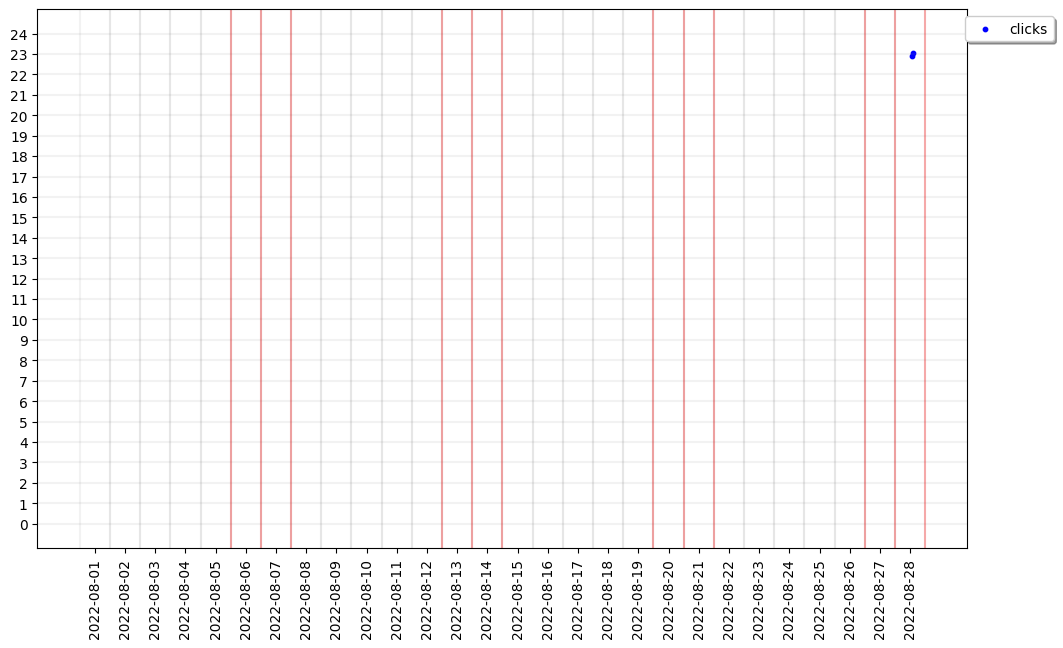

In [ ]:
utils.plot_user_activity(user=12899774, df=df_train)

In [ ]:
df_train["type"].value_counts()

clicks    194720954
carts      16896191
orders      5098951
Name: type, dtype: int64

In [ ]:
df_train["date"].min(), df_train["date"].max()

(Timestamp('2022-08-01 00:00:00.024999936'), Timestamp('2022-08-28 23:59:59.984000'))

In [ ]:
df_test["date"].min(), df_test["date"].max()

(Timestamp('2022-08-29 00:00:00.278000128'), Timestamp('2022-09-04 23:59:51.563000064'))

In [ ]:
%%time

df_train.groupby(['dayofweek', 'type'])[['ts']].count()

CPU times: user 16.9 s, sys: 8.07 s, total: 25 s
Wall time: 24.6 s


ts 
 
 
 dayofweek 
 type 
 
 
 
 
 
 0 
 carts 
 2335991 
 
 
 clicks 
 27514030 
 
 
 orders 
 734694 
 
 
 1 
 carts 
 2442264 
 
 
 clicks 
 27227839 
 
 
 orders 
 788182 
 
 
 2 
 carts 
 2360846 
 
 
 clicks 
 26985981 
 
 
 orders 
 704832 
 
 
 3 
 carts 
 2204026 
 
 
 clicks 
 25538575 
 
 
 orders 
 645485 
 
 
 4 
 carts 
 2274907 
 
 
 clicks 
 26183716 
 
 
 orders 
 659433 
 
 
 5 
 carts 
 2325947 
 
 
 clicks 
 27280343 
 
 
 orders 
 663990 
 
 
 6 
 carts 
 2952210 
 
 
 clicks 
 33990470 
 
 
 orders 
 902335

In [ ]:
%%time

df_test.groupby(['dayofweek', 'type'])[['ts']].count()

CPU times: user 505 ms, sys: 200 ms, total: 705 ms
Wall time: 704 ms


ts 
 
 
 dayofweek 
 type 
 
 
 
 
 
 0 
 carts 
 87577 
 
 
 clicks 
 924175 
 
 
 orders 
 13547 
 
 
 1 
 carts 
 84719 
 
 
 clicks 
 960098 
 
 
 orders 
 10849 
 
 
 2 
 carts 
 87353 
 
 
 clicks 
 949862 
 
 
 orders 
 10755 
 
 
 3 
 carts 
 77150 
 
 
 clicks 
 838805 
 
 
 orders 
 8738 
 
 
 4 
 carts 
 68115 
 
 
 clicks 
 758053 
 
 
 orders 
 7108 
 
 
 5 
 carts 
 73291 
 
 
 clicks 
 850542 
 
 
 orders 
 6649 
 
 
 6 
 carts 
 91806 
 
 
 clicks 
 1011097 
 
 
 orders 
 7834

In [ ]:
df_train_n_session = (df_train.groupby("user")[["n_session"]].max() + 1).reset_index()
df_test_n_session = (df_test.groupby("user")[["n_session"]].max() + 1).reset_index()

In [ ]:
df_train_n_session["n_session"].value_counts()

1      4861373
2      3294399
3      1564799
4       886517
5       558291
6       378977
7       268371
8       198763
9       151469
10      118186
11       94641
12       76397
13       63582
14       52273
15       43830
16       37308
17       31713
18       27244
19       23499
20       20178
21       17605
22       15219
23       13591
24       11891
25       10531
26        9110
27        8054
28        7111
29        6425
30        5533
31        4956
32        4396
33        3893
34        3448
35        3134
36        2684
37        2382
38        2150
39        1893
40        1640
41        1469
42        1372
43        1132
44        1042
45         925
46         754
47         690
48         628
49         538
50         451
51         450
52         352
53         341
54         304
55         238
56         231
58         197
57         182
59         145
60         127
61         102
62          87
63          78
64          73
65          65
67          54
66          41
68          31
69          22
74          22
72          22
70          21
71          18
73          18
75          15
79          12
77          11
76          11
78           6
81           4
84           4
87           4
86           4
82           3
90           3
80           3
93           3
103          2
88           2
85           2
111          1
98           1
92           1
99           1
107          1
91           1
106          1
89           1
127          1
83           1
96           1
100          1
Name: n_session, dtype: int64

In [ ]:
df_test_n_session["n_session"].value_counts()

1     1486287
2      141422
3       29506
4        8839
5        3156
6        1308
7         583
8         310
9         167
10        100
11         60
12         34
13         14
15          6
14          5
16          2
17          2
18          1
19          1
Name: n_session, dtype: int64

In [ ]:
def plot_n_interactions_per_dayofweek(df):
    try:
        df_name = df.name
    except AttributeError:
        df_name = None

    title = "n_interactions per dayofweek"
    if df_name is not None:
        title += f" in {df_name}"

    plt.figure(figsize=(12, 7))
    plt.title(title)
    plt.xlabel("dayofweek")
    plt.ylabel("n_interactions")

    dict_type_inter_offset = dict()
    dict_type_inter_offset["clicks"] = -0.2
    dict_type_inter_offset["carts"] = 0.0
    dict_type_inter_offset["orders"] = 0.2

    dict_type_inter_color = dict()
    dict_type_inter_color["clicks"] = "b"
    dict_type_inter_color["carts"] = "g"
    dict_type_inter_color["orders"] = "r"

    for (dayofweek, type_inter), df_cur in df.groupby(["dayofweek", "type"]):
        ys = df_cur["ts"].count()
        plt.bar(
            dayofweek + dict_type_inter_offset[type_inter],
            ys,
            width=0.2,
            color=dict_type_inter_color[type_inter],
            align="center",
            # label=feature,
            # marker=",",
            # linestyle="dashed",
            alpha=0.6,
        )

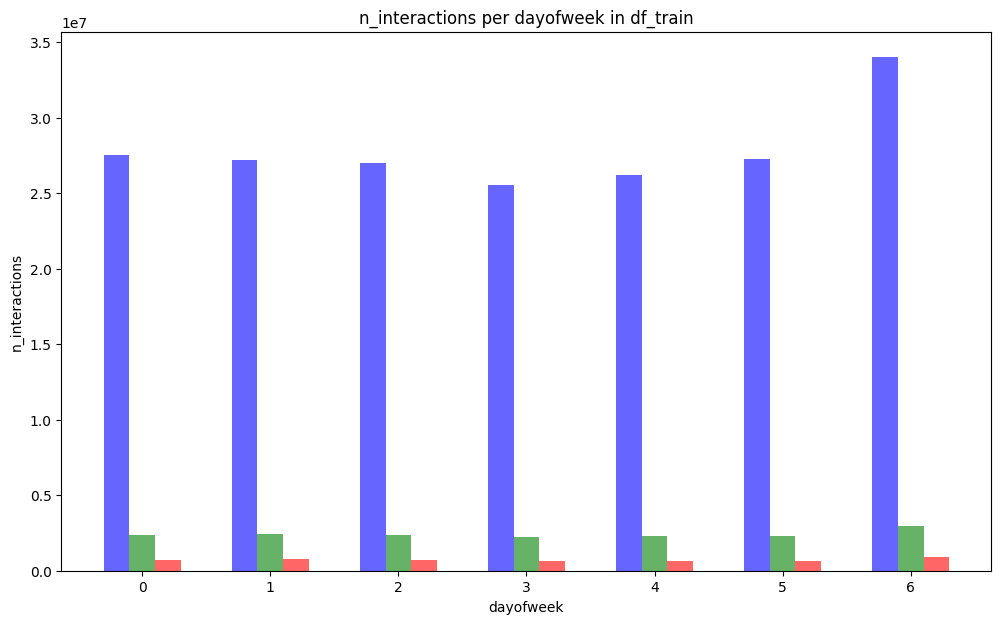

In [ ]:
plot_n_interactions_per_dayofweek(df_train)

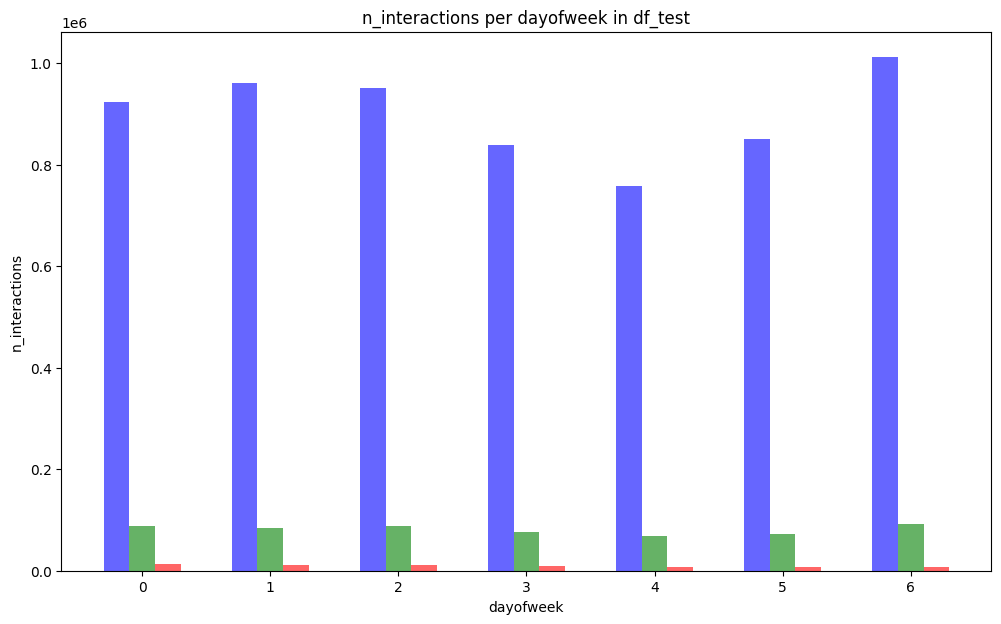

In [ ]:
plot_n_interactions_per_dayofweek(df_test)

In [ ]:
def plot_user_activity(user, df):
    dict_type_inter_color = dict()
    dict_type_inter_color["clicks"] = "b"
    dict_type_inter_color["carts"] = "orange"
    dict_type_inter_color["orders"] = "r"

    offset = 0.5
    df_cur = df[df["user"] == user]
    df_cur["date_day"] = df_cur["date_day"].astype(str)

    if df.name == "df_train":
        x = pd.date_range("2022-08-01", "2022-08-28")
    elif df.name == "df_test":
        x = pd.date_range("2022-08-29", "2022-09-04")
    x = [str(d).split(" ")[0] for d in x]
    map_dates = {x[i]: i for i in range(len(x))}
    points_sundays = [point for point in range(len(x)) if (point + 1) % 7 == 0]

    plt.figure(figsize=(12, 7))
    plt.xticks(range(len(x)), x, rotation=90)
    plt.yticks(range(25))

    for point in range(25):
        plt.axhline(y=point, color="gray", linestyle="-", alpha=0.1)
    for point in range(len(x)):
        plt.axvline(x=point + offset, color="gray", linestyle="-", alpha=0.1)
        plt.axvline(x=point - offset, color="gray", linestyle="-", alpha=0.1)
    for point in points_sundays:
        plt.axvline(x=point + offset, color="r", linestyle="-", alpha=0.3)
        plt.axvline(x=point - offset, color="r", linestyle="-", alpha=0.3)
        plt.axvline(x=point - offset - 1, color="r", linestyle="-", alpha=0.3)

    for action, df_cur_action in df_cur.groupby("type"):
        xx = np.random.uniform(-0.15, 0.15, len(df_cur_action))
        yy = np.random.uniform(-0.15, 0.15, len(df_cur_action))
        plt.scatter(
            df_cur_action["date_day"].map(map_dates) + xx,
            df_cur_action["hour"] + yy,
            c=dict_type_inter_color[action],
            s=10,
            label=action,
        )
    plt.legend(
        loc="upper right", bbox_to_anchor=(1.1, 1.0), ncol=1, fancybox=True, shadow=True
    )

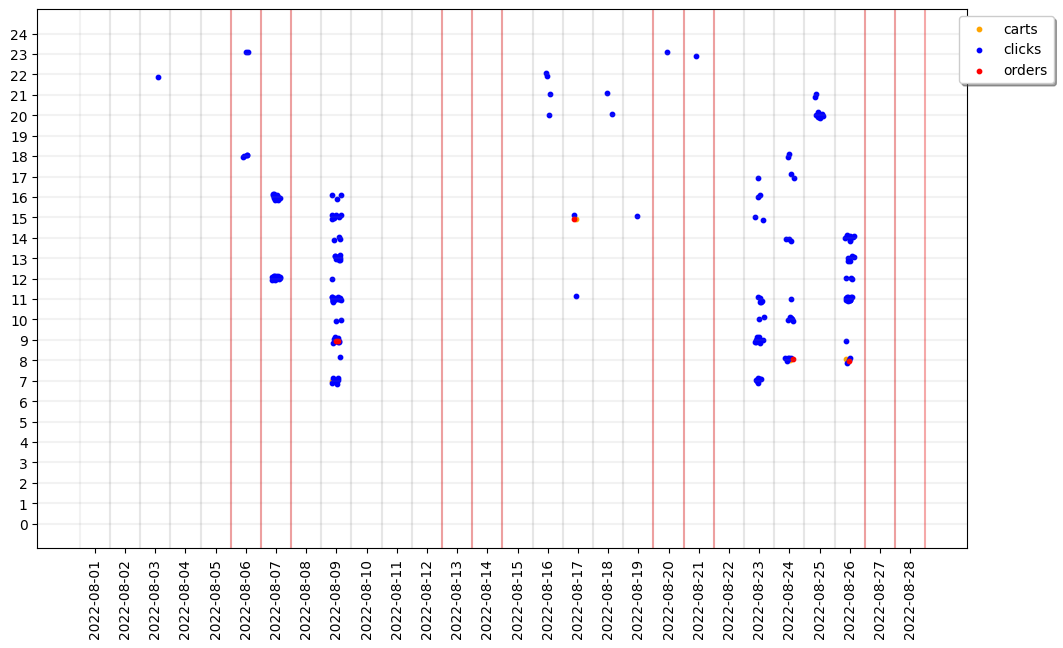

In [ ]:
plot_user_activity(user=2932269, df=df_train)

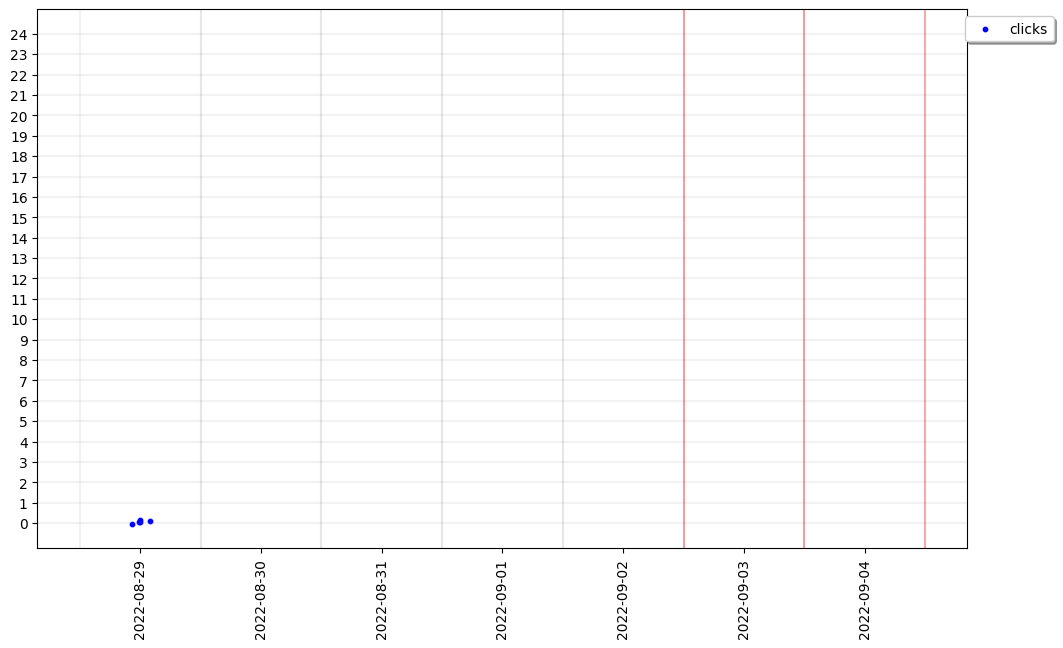

In [ ]:
plot_user_activity(user=12899780, df=df_test)